# Лабораторная работа № 8. Построение пайплайна одномерной регрессии
**Дисциплина:** Методы искусственного интеллекта  
**Студент:** Мальцев Николай Артемович  
**Группа:** ИНС-м-о-25-2

**Цель:** разработка единого пайплайна для решения задачи регрессии.

**Задачи:** реализовать все стадии одномерной регрессии; изучить задачу регрессии; освоить использование пайплайна и рефакторинг кода.

**Данные:** `Salary_Data.csv` для учебного примера; прежний RCAEval RE2-OB для индивидуального задания.

Работа выполнена по лабораторной № 8 методички *Practicum_AI_Methods.pdf*, с. 90–95.

## 1. Локальный запуск и общий шаблон
Используем прежнее Conda-окружение `rcaeval-ai`. В VS Code выбираем его ядро и выполняем **Run All**. Для работы № 9 в `environment.yml` добавлен `statsmodels=0.14`. Обновить окружение из корня можно командой:
```bash
conda env update --prefix .conda/rcaeval-ai -f environment.yml
```

Ноутбук работает из корня проекта и из `notebooks/`. RCAEval уже сохранён на компьютере; повторное скачивание не выполняется. Таблицы и рисунки записываются в папку этой работы внутри `reports/`.

**Пайплайн** — последовательность шагов, которая одинаково готовит обучающие данные и новые строки. Сначала отделяем проверочные данные, затем вызываем `fit` только для обучения. Для проверки используются сохранённые средние, масштаб и категории.

Подключаем библиотеки для таблиц и графиков.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from importlib.metadata import version
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

Подключаем средства подготовки данных и регрессии.

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

Задаём пути и настройки.

In [3]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'environment.yml').is_file() and (p / 'notebooks').is_dir())
REPORT = ROOT / 'reports/lab08'
FIGURES = REPORT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
EXAMPLES = ROOT / 'data/raw/pipeline_examples'
EXAMPLES.mkdir(parents=True, exist_ok=True)
SEED = 17
sns.set_theme(style='whitegrid')

Печатаем и сохраняем версии.

In [4]:
versions = {'Python': platform.python_version()}
versions.update({name: version(name) for name in ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scikit-learn', 'statsmodels']})
display(pd.Series(versions, name='Версия'))
(REPORT / 'versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')

Python          3.11.17
pandas            2.3.3
numpy             2.2.6
matplotlib       3.10.9
seaborn          0.13.2
scikit-learn      1.7.2
statsmodels      0.14.6
Name: Версия, dtype: object

169

Определяем функцию сохранения и показа рисунков.

In [5]:
def save_show(fig, name):
    fig.savefig(FIGURES / name, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

### 1.1. Переиспользуемый шаблон подготовки
Для числовых столбцов заполняем пропуски средним значением обучения. Масштабирование можно включить или отключить. `StandardScaler` вычитает среднее и делит на стандартное отклонение.

Для категорий заполняем пропуски наиболее частой категорией и используем `OneHotEncoder`: отдельные столбцы 0/1. Одну категорию оставляем базовой (`drop='first'`), чтобы вместе со свободным членом не создавать избыточные столбцы. Названия преобразованных признаков сохраняются.

Эта функция одинаковая в работах № 7, 8 и 9. Для новой задачи меняются списки столбцов и последний шаг модели. Каждый ноутбук содержит её определение и запускается самостоятельно.

Определяем общий шаблон предварительной обработки.

In [6]:
def make_preprocessor(numeric, categorical, scale=True):
    numeric_steps = [('impute', SimpleImputer(strategy='mean'))]
    if scale:
        numeric_steps.append(('scale', StandardScaler()))
    categorical_steps = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
    ])
    return ColumnTransformer([
        ('numeric', Pipeline(numeric_steps), numeric),
        ('categorical', categorical_steps, categorical)
    ], verbose_feature_names_out=False).set_output(transform='pandas')

Определяем функцию расчёта ошибок регрессии.

In [7]:
def regression_scores(actual, predicted):
    return {'MSE': mean_squared_error(actual, predicted),
            'MAE': mean_absolute_error(actual, predicted),
            'R2': r2_score(actual, predicted)}

Одномерная линейная регрессия имеет **один входной признак** и один числовой ответ. Она подбирает прямую `y = a + b·x`, минимизируя сумму квадратов ошибок обучения.

MSE — средняя квадратичная ошибка, MAE — средняя ошибка по модулю. Чем меньше, тем лучше. R² = 1 означает точное совпадение, R² = 0 — качество постоянного среднего проверочной части; значение может быть отрицательным. В таблицах отдельно сравниваем модель с baseline по среднему **обучения**.

### 1.2. От подготовки к модели
Берём шаблон из работы № 7 и добавляем LinearRegression. В этой работе масштабирование отключаем: для обычной одномерной регрессии оно не требуется, а коэффициент проще читать в исходной шкале. Заполнение пропусков остаётся частью шаблона.

Определяем функцию создания полного пайплайна регрессии.

In [8]:
def make_linear_pipeline(numeric, categorical=(), scale=False):
    return Pipeline([
        ('prepare', make_preprocessor(list(numeric), list(categorical), scale=scale)),
        ('regression', LinearRegression())
    ])

Определяем функцию показа точек и обученной прямой.

In [9]:
def line_plot(model, X, y, title, xlabel, ylabel, filename):
    grid = pd.DataFrame({X.columns[0]: np.linspace(X.iloc[:, 0].min(), X.iloc[:, 0].max(), 200)})
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.scatter(X.iloc[:, 0], y, s=25, alpha=0.55, label='Настоящие значения')
    ax.plot(grid.iloc[:, 0], model.predict(grid), color='darkorange', linewidth=2, label='Обученная прямая')
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.legend()
    save_show(fig, filename)

## 2. Учебная задача: опыт и зарплата
### 2.1. Загрузка и разделение
Повторяем пример рис. 8.1: один признак `YearsExperience`, ответ `Salary`, 25% для проверки, LinearRegression, предсказания и отдельные рисунки обучения и проверки. Это опубликованная учебная таблица, а не индивидуальные данные мониторинга. Точные денежные единицы в CSV не указаны.

Получаем учебный CSV, если его ещё нет на компьютере.

In [10]:
example_path = EXAMPLES / 'Salary_Data.csv'
example_revision = '66d3cdbd8a19102c54750d8e8bd834845c7eedef'
example_url = f'https://raw.githubusercontent.com/murphymv/Machine-Learning-A-Z/{example_revision}/Salary_Data.csv'
if not example_path.exists():
    example_path.write_bytes(urlopen(example_url, timeout=60).read())

Читаем учебный файл.

In [11]:
salary = pd.read_csv(example_path)

Печатаем первые строки, размеры и пропуски.

In [12]:
display(salary.head())
print('Размер:', salary.shape)
display(salary.isna().sum().rename('Пропуски'))

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


Размер: (30, 2)


YearsExperience    0
Salary             0
Name: Пропуски, dtype: int64

Выделяем один признак и делим таблицу, как в примере.

In [13]:
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    salary[['YearsExperience']], salary.Salary, test_size=0.25, random_state=0)
print('Обучение:', len(Xs_train), '| Проверка:', len(Xs_test))

Обучение: 22 | Проверка: 8


Обучаем полный пайплайн на обучающих строках.

In [14]:
salary_model = make_linear_pipeline(['YearsExperience'])
salary_model.fit(Xs_train, ys_train)

,steps,"[('prepare', ...), ('regression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


Получаем ответы и считаем ошибки на отложенных строках.

In [15]:
salary_prediction = salary_model.predict(Xs_test)
display(pd.DataFrame({'Опыт': Xs_test.YearsExperience, 'Настоящая зарплата': ys_test,
                      'Ответ модели': salary_prediction}))
salary_scores = regression_scores(ys_test, salary_prediction)
display(pd.Series(salary_scores, name='Проверка'))

,Опыт,Настоящая зарплата,Ответ модели
2,1.5,37731.0,41056.257055
28,10.3,122391.0,123597.709384
13,4.1,57081.0,65443.504334
10,3.9,63218.0,63567.562235
26,9.5,116969.0,116093.940990
24,8.7,109431.0,108590.172597
27,9.6,112635.0,117031.912039
11,4.0,55794.0,64505.533285


MSE    2.240794e+07
MAE    3.508546e+03
R2     9.779208e-01
Name: Проверка, dtype: float64

Показываем прямую на обучающих данных.

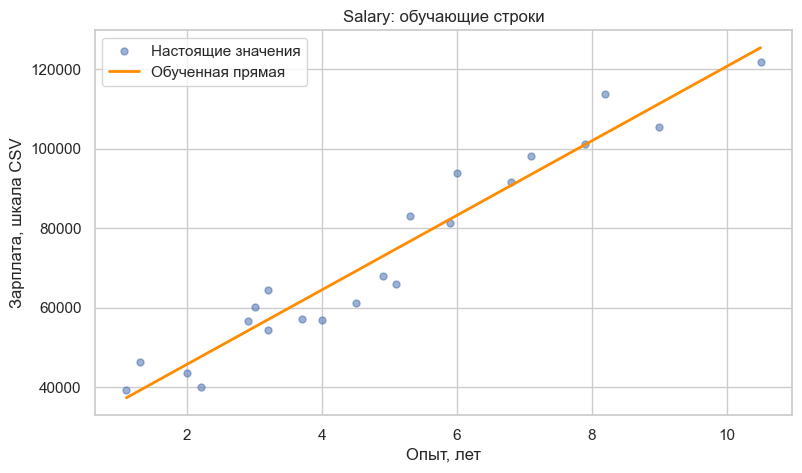

In [16]:
line_plot(salary_model, Xs_train, ys_train, 'Salary: обучающие строки',
          'Опыт, лет', 'Зарплата, шкала CSV', '01_salary_training.png')

Точки — зарплаты обучающих строк, линия — подобранная зависимость от опыта. Вертикальное расстояние от точки до линии означает ошибку. Модель получает общую тенденцию, а не обязана проходить через каждую точку.

Показываем ту же обученную прямую на проверочных данных.

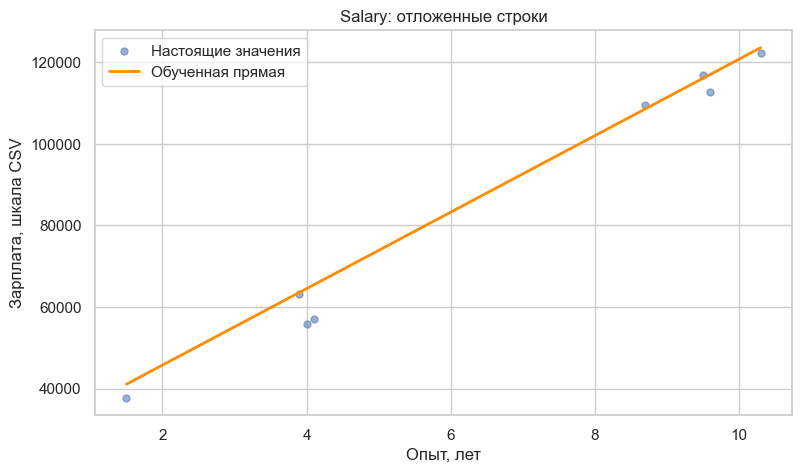

In [17]:
line_plot(salary_model, Xs_test, ys_test, 'Salary: отложенные строки',
          'Опыт, лет', 'Зарплата, шкала CSV', '02_salary_test.png')

Эти точки не участвовали в обучении. Прямую заново не подбираем: используем сохранённый пайплайн. Так проверяем, насколько правило подходит к новым для него строкам.

## 3. Индивидуальное задание: оценка памяти по CPU

### 3.1. Прежний набор данных
RCAEval содержит измерения микросервисов Online Boutique во время одного CPU-эксперимента. Используем тот же сценарий из первой работы. Новые сценарии не добавляем. Единицы отдельных показателей в локальном файле не указаны: сохраняем исходные шкалы или явно подписываем деление на миллион.

**Согласование датасета с преподавателем:** ____________________  
**Дата:** ____________________

Читаем сохранённое имя сценария.

In [18]:
selection = json.loads((ROOT / 'reports/lab01/selected_case.json').read_text(encoding='utf-8'))
case = selection['case']
case_dir = ROOT / 'data/raw/rcaeval' / case

Загружаем локальные метрики и время внесения сбоя.

In [19]:
metrics_path = case_dir / 'metrics.parquet'
inject_path = case_dir / 'inject_time.txt'
df = pd.read_parquet(metrics_path)
inject_time = int(inject_path.read_text(encoding='utf-8').strip())

Показываем первые строки и размер таблицы.

In [20]:
display(df.head())
print('Сценарий:', case, '| Сервис:', selection['root_cause_service'], '| Тип сбоя:', selection['fault'])
print('Строк:', len(df), '| Метрик:', df.shape[1] - 1, '| Пропусков:', int(df.isna().sum().sum()))

,time,adservice_cpu,cartservice_cpu,checkoutservice_cpu,currencyservice_cpu,emailservice_cpu,frontend_cpu,paymentservice_cpu,productcatalogservice_cpu,recommendationservice_cpu,...,adservice_latency-90,cartservice_latency-90,checkoutservice_latency-90,currencyservice_latency-90,emailservice_latency-90,frontend_latency-90,paymentservice_latency-90,productcatalogservice_latency-90,recommendationservice_latency-90,shippingservice_latency-90
0,1705353846,0.685023,2.216467,0.215886,19.035876,0.279166,6.724489,0.52931,2.636831,2.474853,...,0.004604,0.004993,0.850000,0.110638,0.0046,0.819737,0.008955,0.004418,0.009670,0.004576
1,1705353847,0.685023,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.636858,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008955,0.004423,0.009672,0.004576
2,1705353848,0.582707,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.584059,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008636,0.004423,0.009672,0.004576
3,1705353849,0.625903,2.216467,0.380058,19.106596,0.279166,6.724489,0.52931,3.250317,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576
4,1705353850,0.613414,2.216467,0.380058,19.106596,0.279166,5.572668,0.52931,3.250317,2.474853,...,0.004594,0.006304,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576


Сценарий: re2ob_checkoutservice_cpu_1 | Сервис: checkoutservice | Тип сбоя: cpu
Строк: 1441 | Метрик: 72 | Пропусков: 4


### 3.2. Отложенные данные
Соседние измерения похожи, поэтому оставляем целые минутные участки для проверки. Внешнее разделение учитывает периоды до и после внесения, чтобы они были представлены в обеих частях. Период и время не входят в признаки регрессии.

Это оценка текущего показателя по другим метрикам в рамках одного эксперимента. Модель не прогнозирует будущее и не проверяется здесь на другом сбое.

Выбираем минутные участки для обучения и проверки.

In [21]:
minute_groups = ((df.time - df.time.min()) // 60).astype(int)
period = (df.time >= inject_time).astype(int)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter.split(df, period, minute_groups))
print('Обучение:', len(train_idx), '| Проверка:', len(test_idx))

Обучение: 1141 | Проверка: 300


### 3.3. Один входной признак
Для checkoutservice используем **CPU → память** в тот же момент. Это связь метрик одного сервиса в одном CPU-эксперименте. Память делим на миллион, чтобы подписи и ошибки были читаемыми. Это миллионы исходных единиц, а не автоматически мегабайты.

В модели только CPU. Память является ответом; время, метка периода и другие показатели не входят в X. Хорошая связь двух метрик не доказывает, что изменение CPU вызвало изменение памяти.

Выбираем признак и числовой ответ.

In [22]:
feature = 'checkoutservice_cpu'
target = 'checkoutservice_mem'
X = df[[feature]].copy()
y = df[target] / 1e6
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
display(df[[feature, target]].isna().sum().rename('Пропуски'))

checkoutservice_cpu    0
checkoutservice_mem    0
Name: Пропуски, dtype: int64

Пропусков в этих двух столбцах нет. Шаблон не создаёт и не меняет значения при заполнении: он готов и для таблицы, где пропуски появятся.

Обучаем тот же пайплайн на CPU и памяти.

In [23]:
model = make_linear_pipeline([feature])
model.fit(X_train, y_train)
prediction = model.predict(X_test)

Сравниваем модель с постоянным средним обучения.

In [24]:
mean_prediction = np.full(len(y_test), y_train.mean())
metrics = pd.DataFrame([regression_scores(y_test, mean_prediction), regression_scores(y_test, prediction)],
                       index=['Среднее обучения', 'Одномерная регрессия'])
display(metrics)

,MSE,MAE,R2
Среднее обучения,5.295515,2.289958,-0.063386
Одномерная регрессия,0.091665,0.256717,0.981593


Все ошибки рассчитаны на одинаковых отложенных минутах. MAE имеет ту же шкалу, что и память после деления на миллион. Таблица показывает, полезнее ли учитывать CPU, чем всегда выдавать одно среднее число. Эти результаты не используются для повторного обучения прямой.

Показываем коэффициенты уравнения в исходной шкале CPU.

In [25]:
intercept = float(model.named_steps['regression'].intercept_)
slope = float(model.named_steps['regression'].coef_[0])
print(f'Память / 1 000 000 = {intercept:.4f} + {slope:.4f} × CPU')

Память / 1 000 000 = 11.7526 + 0.2413 × CPU


Свободный член задаёт ответ прямой при CPU = 0, наклон — изменение её ответа при увеличении CPU на одну исходную единицу. Это коэффициенты описания выбранных данных; их не следует считать универсальным правилом сервиса.

Строим прямую и обучающие измерения RCAEval.

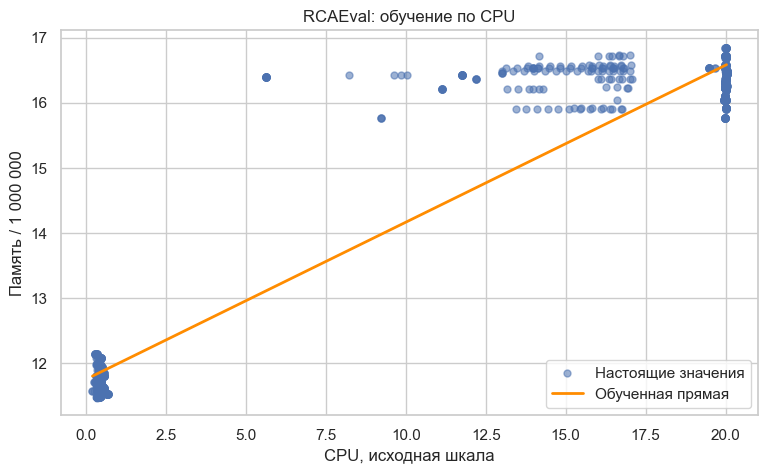

In [26]:
line_plot(model, X_train, y_train, 'RCAEval: обучение по CPU',
          'CPU, исходная шкала', 'Память / 1 000 000', '03_rca_training.png')

Измерения группируются около низких и высоких значений CPU. Прямая связывает эти группы. В промежутке между ними мало наблюдений, поэтому рисунок не подтверждает качество для всех промежуточных нагрузок.

Показываем ту же прямую на отложенных измерениях.

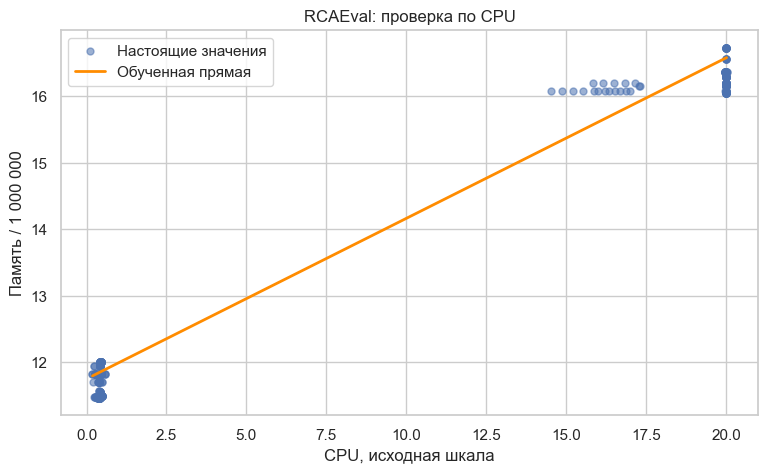

In [27]:
line_plot(model, X_test, y_test, 'RCAEval: проверка по CPU',
          'CPU, исходная шкала', 'Память / 1 000 000', '04_rca_test.png')

Точки принадлежат отложенным минутам. Их отклонения от линии показывают ошибки оценки памяти по одному CPU. Даже при хорошей общей связи значения памяти внутри каждой группы немного различаются.

Сравниваем настоящий ответ с прогнозом модели.

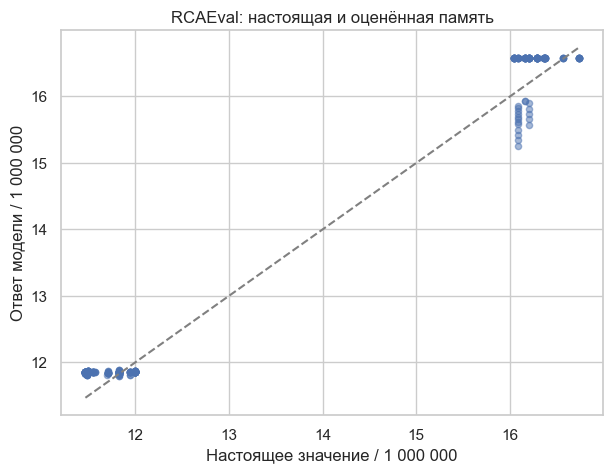

In [28]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(y_test, prediction, s=20, alpha=0.5)
low, high = min(y_test.min(), prediction.min()), max(y_test.max(), prediction.max())
ax.plot([low, high], [low, high], '--', color='gray')
ax.set(title='RCAEval: настоящая и оценённая память', xlabel='Настоящее значение / 1 000 000',
       ylabel='Ответ модели / 1 000 000')
save_show(fig, '05_rca_actual_predicted.png')

Пунктир показывает идеальное совпадение. Точки над ним означают завышенный ответ, под ним — заниженный. Здесь удобнее заметить ошибку, чем на графике CPU, потому что по обеим осям стоит память в одной шкале.

Показываем ошибки во времени.

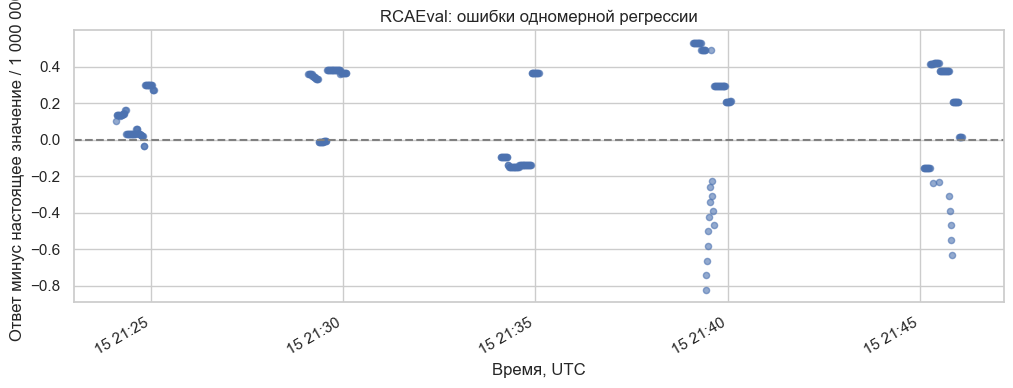

In [29]:
answers = pd.DataFrame({'row': X_test.index, 'time': df.time.iloc[test_idx].to_numpy(),
                        'actual': y_test.to_numpy(), 'prediction': prediction})
answers['error'] = answers.prediction - answers.actual
ordered = answers.sort_values('time')
fig, ax = plt.subplots(figsize=(12, 4))
ax.scatter(pd.to_datetime(ordered.time, unit='s', utc=True), ordered.error, s=20, alpha=0.6)
ax.axhline(0, color='gray', linestyle='--')
ax.set(title='RCAEval: ошибки одномерной регрессии', xlabel='Время, UTC',
       ylabel='Ответ минус настоящее значение / 1 000 000')
fig.autofmt_xdate()
save_show(fig, '06_rca_errors.png')

Каждая точка — ошибка на отложенной строке. Выше нуля модель завысила память, ниже — занизила. Промежутки между группами возникают из-за выбора целых минут для проверки. По рисунку видно, одинаковы ли ошибки в разных участках эксперимента.

Формируем и сохраняем простой текст результата.

In [30]:
model_scores = regression_scores(y_test, prediction)
word = 'меньше' if model_scores['MSE'] < metrics.loc['Среднее обучения', 'MSE'] else 'не меньше'
analysis = (f'Разработал единый пайплайн одномерной регрессии. В примере изучил связь опыта и зарплаты. '
            f'Для {case} оценивал память checkoutservice по одному CPU. '
            f'На {len(y_test)} отложенных строках MAE = {model_scores["MAE"]:.4f} в миллионах исходных единиц памяти; R² = {model_scores["R2"]:.3f}. '
            f'Ошибка модели {word} ошибки постоянного среднего обучения. '
            'Подготовка и модель обучались только на обучающих минутах. Результат описывает один эксперимент и не является прогнозом будущего.')
display(Markdown(analysis))
(REPORT / 'analysis.md').write_text(analysis, encoding='utf-8')
metrics.to_csv(REPORT / 'regression_metrics.csv', index_label='model')
answers.to_csv(REPORT / 'predictions.csv', index=False)
summary = {'case': case, 'feature': feature, 'target': target, 'target_scale': 'original / 1e6',
           'train_rows': len(X_train), 'test_rows': len(X_test), 'intercept': intercept, 'slope': slope,
           'regression': model_scores, 'salary_test': salary_scores}

Разработал единый пайплайн одномерной регрессии. В примере изучил связь опыта и зарплаты. Для re2ob_checkoutservice_cpu_1 оценивал память checkoutservice по одному CPU. На 300 отложенных строках MAE = 0.2567 в миллионах исходных единиц памяти; R² = 0.982. Ошибка модели меньше ошибки постоянного среднего обучения. Подготовка и модель обучались только на обучающих минутах. Результат описывает один эксперимент и не является прогнозом будущего.

Сохраняем сведения об исходных файлах и список рисунков.

In [31]:
sources = {'example_url': example_url, 'example_revision': example_revision, 'rcaeval': selection,
           'sha256': {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest()
                      for path in [example_path, metrics_path, inject_path]}}
(REPORT / 'sources.json').write_text(json.dumps(sources, ensure_ascii=False, indent=2), encoding='utf-8')
summary['figures'] = sorted(path.name for path in FIGURES.glob('*.png'))
(REPORT / 'results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')

673

## 4. Заключение
Разработал единый пайплайн для решения задачи регрессии. Научился добавлять к подготовке данных обучение LinearRegression, получать числовые ответы и проверять ошибки на отложенных строках.

На учебном примере оценивал зарплату по опыту, на RCAEval — текущую память по CPU. Повторно использовал функцию подготовки из работы № 7. Графики помогли увидеть обученную прямую и её ошибки; проверка со средним ответом позволила оценить пользу одного признака.

## 5. Ответы на контрольные вопросы
**1. Почему масштабирование не обязательно?**  
Для обычной линейной регрессии без регуляризации изменение масштаба признака меняет его коэффициент, но в точной арифметике не меняет подобранные ответы. Масштабирование может помочь при плохо обусловленных данных. Для моделей с регуляризацией масштаб уже важен.

**2. Почему используют квадрат ошибки, а не модуль?**  
Квадрат гладко меняется, удобен для вычисления и сильнее учитывает крупные ошибки. Это соответствует методу наименьших квадратов. Модуль тоже допустим, но задаёт другую задачу оптимизации и менее гладкую функцию.

**3. Что делает LinearRegression.fit(X, y)?**  
Подбирает веса и свободный член, которые минимизируют сумму квадратов ошибок на переданных обучающих строках. В пайплайне перед этим обучается подготовка признаков.

**4. Что такое p-значение и как оно используется?**  
При гипотезе «коэффициент равен нулю» p-значение показывает вероятность получить такое же или более сильное отклонение оценки от нуля при выполнении предположений теста. Это не вероятность истинности гипотезы. В регрессии его используют как один из критериев удаления признаков. Сам LinearRegression p-значения не рассчитывает; в работе № 9 для этого используется statsmodels. Отбор выполняют по обучению.

**5. Для чего predict?**  
Получает ответы обученной модели для новых строк. В пайплайне автоматически применяет сохранённую подготовку.

**6. Для чего plot и scatter?**  
`scatter` показывает отдельные наблюдения точками. `plot` соединяет значения линией; здесь он показывает ответ регрессии на упорядоченной сетке CPU или опыта.

**7. На какой части оценивать качество?**  
На отложенной тестовой части, которая не участвовала в обучении и выборе модели. Ошибка обучения полезна для диагностики, но не заменяет проверку на новых строках.

## 6. Источники
- Методичка `Practicum_AI_Methods.pdf`, раздел этой лабораторной работы.
- [Учебные таблицы Machine Learning A–Z](https://github.com/murphymv/Machine-Learning-A-Z/tree/66d3cdbd8a19102c54750d8e8bd834845c7eedef) — копии CSV примеров; они не заменяют индивидуальный датасет мониторинга.
- [RCAEval](https://huggingface.co/datasets/phamquiluan/RCAEval).
- [scikit-learn: ColumnTransformer](https://scikit-learn.org/1.7/modules/generated/sklearn.compose.ColumnTransformer.html).
- [scikit-learn: LinearRegression](https://scikit-learn.org/1.7/modules/generated/sklearn.linear_model.LinearRegression.html).